# Global Solution CitizenTech — O custo invisível do café
Análise estatística de 8 marcas fictícias de café em cápsulas (640 cápsulas por marca). Notebook reproduzível: lê os CSVs de `../dados` e gera os números do PDF de 1 página.

**Definição de "melhor":** menor dano ponderado **por g de café** (a massa de café difere entre marcas), combinando indicadores sociais, climáticos, ambientais e de pós-consumo (reciclagem *efetiva*, não "reciclável" nem "coletada").

In [1]:
import pandas as pd, numpy as np, glob, warnings
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore'); pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
df=pd.concat([pd.read_csv(f) for f in sorted(glob.glob('../dados/*.csv'))],ignore_index=True)
M=['Aurora','Bravura','Cerrado','Delta','Estacao','Flora','Granito','Horizonte']
print(df.shape, df.capsula_id.is_unique)
print('soma das parcelas = total? max erro:',(df.co2e_total_g-df[['co2e_producao_g','co2e_logistica_g','co2e_fim_vida_g']].sum(axis=1)).abs().max())
print(df.groupby('marca').material_embalagem.first().to_dict())

(5120, 21) True
soma das parcelas = total? max erro: 0.010000000000047748
{'Aurora': 'aluminio', 'Bravura': 'plastico', 'Cerrado': 'compostavel', 'Delta': 'aluminio', 'Estacao': 'plastico', 'Flora': 'fibra_mista', 'Granito': 'aluminio', 'Horizonte': 'plastico'}


## 1. Qualidade dos dados
NaN em indicadores sociais = **não auditado** (nunca 'sem irregularidade'): o denominador correto é o conjunto de cápsulas auditadas.

In [2]:
print(df.isna().sum()[lambda s:s>0])
print('NaN só onde não houve auditoria:',df[df.auditoria_fornecedor_realizada==0].nao_conformidade_trabalhista.isna().all(), df[df.auditoria_fornecedor_realizada==1].nao_conformidade_trabalhista.notna().all())
aud=df.groupby('marca').auditoria_fornecedor_realizada.agg(['sum','mean']); aud.columns=['auditadas','prop']; print(aud.round(3))
print('Estação vs demais, chi2 p =',stats.chi2_contingency(pd.crosstab(df.marca=='Estacao',df.auditoria_fornecedor_realizada))[1])

nao_conformidade_trabalhista    1582
trabalho_infantil_constatado    1582
dtype: int64
NaN só onde não houve auditoria: True True
           auditadas   prop
marca                      
Aurora           498  0.778
Bravura          468  0.731
Cerrado          482  0.753
Delta            480  0.750
Estacao          171  0.267
Flora            481  0.752
Granito          477  0.745
Horizonte        481  0.752
Estação vs demais, chi2 p = 2.380032462739566e-135


## 2. Unidade funcional: por g de café
A massa de café varia entre marcas; dividimos CO₂e, água, desmatamento e efluentes por `massa_cafe_g`.

In [3]:
print('ANOVA massa_cafe_g: p =',stats.f_oneway(*[df[df.marca==m].massa_cafe_g for m in M]).pvalue)
for c in ['co2e_total_g','agua_total_l','desmatamento_atribuido_m2','indice_efluentes_toxicos']: df[c+'_pg']=df[c]/df.massa_cafe_g
def tci(s):
    h=stats.t.ppf(.975,len(s)-1)*s.sem(); return s.mean(),s.mean()-h,s.mean()+h
rows=[]
for c in ['co2e_total_g_pg','agua_total_l_pg','desmatamento_atribuido_m2_pg','indice_efluentes_toxicos_pg','co2e_total_g','remuneracao_relativa_referencia']:
    for m in M: rows.append((c,m)+tuple(np.round(tci(df[df.marca==m][c]),3)))
T=pd.DataFrame(rows,columns=['indicador','marca','media','ic_inf','ic_sup']); display(T.pivot(index='marca',columns='indicador',values='media'))
for c in ['co2e_total_g_pg','agua_total_l_pg','desmatamento_atribuido_m2_pg','indice_efluentes_toxicos_pg','remuneracao_relativa_referencia']:
    g=[df[df.marca==m][c] for m in M]; print(c,'ANOVA p=%.2g | Kruskal p=%.2g | Levene p=%.2g'%(stats.f_oneway(*g).pvalue,stats.kruskal(*g).pvalue,stats.levene(*g).pvalue))
print('assimetria (agua/desm/efluentes) -> conferimos com Kruskal e t de Welch (n=640, TCL)')

ANOVA massa_cafe_g: p = 2.020541908686557e-71


indicador,agua_total_l_pg,co2e_total_g,co2e_total_g_pg,desmatamento_atribuido_m2_pg,indice_efluentes_toxicos_pg,remuneracao_relativa_referencia
marca,,,,,,
Aurora,2.304,179.241,32.759,0.207,0.143,0.682
Bravura,2.812,145.056,25.837,0.277,0.228,0.662
Cerrado,3.573,155.190,27.339,0.252,0.149,0.687
Delta,1.932,215.154,37.242,0.173,0.114,0.692
Estacao,2.925,164.633,28.031,0.290,0.252,0.654
Flora,3.307,168.693,28.487,0.222,0.163,0.675
Granito,2.031,194.795,32.290,0.255,0.175,0.662
Horizonte,2.545,173.572,28.249,0.274,0.189,0.674


co2e_total_g_pg ANOVA p=0 | Kruskal p=1e-268 | Levene p=4.1e-10
agua_total_l_pg ANOVA p=3.2e-199 | Kruskal p=1.5e-207 | Levene p=9.3e-46
desmatamento_atribuido_m2_pg ANOVA p=2.1e-39 | Kruskal p=2.3e-37 | Levene p=6.6e-24
indice_efluentes_toxicos_pg ANOVA p=4.3e-107 | Kruskal p=8.7e-91 | Levene p=6.3e-61
remuneracao_relativa_referencia ANOVA p=4.7e-06 | Kruskal p=1.1e-05 | Levene p=0.88
assimetria (agua/desm/efluentes) -> conferimos com Kruskal e t de Welch (n=640, TCL)


## 3. Taxas: reciclagem, coleta e indicadores sociais (IC de Wilson)

In [4]:
def rate(d,col):
    x=d[col].dropna(); k,n=int(x.sum()),len(x); lo,hi=proportion_confint(k,n,method='wilson'); return pd.Series({'k':k,'n':n,'p%':100*k/n,'ic_inf%':100*lo,'ic_sup%':100*hi})
aud_df=df[df.auditoria_fornecedor_realizada==1]
for nome,base,col in [('Reciclagem efetiva (todas)',df,'reciclagem_efetiva'),('Coleta pós-consumo (todas)',df,'coleta_pos_consumo'),('Trabalho infantil (auditadas)',aud_df,'trabalho_infantil_constatado'),('Não conformidade trabalhista (auditadas)',aud_df,'nao_conformidade_trabalhista')]:
    print(nome); print(base.groupby('marca').apply(rate,col=col).round(1)); print('  chi2 p = %.2g'%stats.chi2_contingency(pd.crosstab(base.marca,base[col]))[1])
print('Sem coleta: reciclados =',int(df[df.coleta_pos_consumo==0].reciclagem_efetiva.sum()),'de',(df.coleta_pos_consumo==0).sum())
print('Com coleta: %% reciclados = %.1f (n=%d)'%(100*df[df.coleta_pos_consumo==1].reciclagem_efetiva.mean(),(df.coleta_pos_consumo==1).sum()))
print('Remuneração < 1 (todas as marcas):',df.groupby('marca').apply(lambda g:(g.remuneracao_relativa_referencia<1).mean()).round(3).to_dict())
print('Estação, limites p/ trabalho infantil por cápsula: %.1f%% a %.1f%%'%(100*36/640,100*(36+640-171)/640))

Reciclagem efetiva (todas)
               k      n    p%  ic_inf%  ic_sup%
marca                                          
Aurora     188.0  640.0  29.4     26.0     33.0
Bravura    273.0  640.0  42.7     38.9     46.5
Cerrado    183.0  640.0  28.6     25.2     32.2
Delta      132.0  640.0  20.6     17.7     23.9
Estacao    224.0  640.0  35.0     31.4     38.8
Flora      194.0  640.0  30.3     26.9     34.0
Granito    168.0  640.0  26.2     23.0     29.8
Horizonte  201.0  640.0  31.4     27.9     35.1
  chi2 p = 4.4e-16
Coleta pós-consumo (todas)
               k      n    p%  ic_inf%  ic_sup%
marca                                          
Aurora     385.0  640.0  60.2     56.3     63.9
Bravura    455.0  640.0  71.1     67.5     74.5
Cerrado    373.0  640.0  58.3     54.4     62.0
Delta      330.0  640.0  51.6     47.7     55.4
Estacao    423.0  640.0  66.1     62.3     69.7
Flora      386.0  640.0  60.3     56.5     64.0
Granito    360.0  640.0  56.2     52.4     60.0
Horizonte  406.

## 4. Fim de vida e alegações dos documentos

In [5]:
print('co2e_fim_vida_g por destinação (média):'); print(df.groupby(['marca','destinacao_final']).co2e_fim_vida_g.mean().unstack().round(1))
print(df.groupby('marca')[['co2e_producao_g','co2e_logistica_g','co2e_fim_vida_g','co2e_total_g','massa_embalagem_g']].mean().round(1))
print('Horizonte: coletada %.1f%% vs reciclada %.1f%%'%tuple(100*df[df.marca=='Horizonte'][['coleta_pos_consumo','reciclagem_efetiva']].mean()))

co2e_fim_vida_g por destinação (média):


destinacao_final  aterro_ou_rejeito  coprocessamento  reciclagem
marca                                                           
Aurora                         34.8             34.1        35.5
Bravura                        34.6             36.9        35.4
Cerrado                        34.9             34.6        35.4
Delta                          35.1             32.4        33.9
Estacao                        34.8             35.8        34.2
Flora                          34.0             36.6        35.3
Granito                        35.2             33.8        34.8
Horizonte                      35.2             37.5        34.0
           co2e_producao_g  co2e_logistica_g  co2e_fim_vida_g  co2e_total_g  massa_embalagem_g
marca                                                                                         
Aurora               109.4              34.9             35.0         179.2                6.5
Bravura               91.4              18.5             35.1    

## 5. Comparações pareadas com correção de Holm
Welch (médias) e z de duas proporções (diferença com IC de Wald); 7 comparações contra a referência.

In [6]:
def welch(c,ref):
    r=[]
    for m in M:
        if m==ref: continue
        x,y=df[df.marca==ref][c],df[df.marca==m][c]; d=x.mean()-y.mean(); vx,vy=x.var()/len(x),y.var()/len(y); se=np.sqrt(vx+vy)
        dfw=se**4/(vx**2/(len(x)-1)+vy**2/(len(y)-1)); h=stats.t.ppf(.975,dfw)*se
        r.append([m,d,d-h,d+h,stats.ttest_ind(x,y,equal_var=False).pvalue])
    o=pd.DataFrame(r,columns=['vs','dif','ic_inf','ic_sup','p']); o['p_holm']=multipletests(o.p,method='holm')[1]; return o.round(3)
def prop(d,col,ref):
    r=[]
    for m in M:
        if m==ref: continue
        x,y=d[d.marca==ref][col].dropna(),d[d.marca==m][col].dropna(); p1,p2=x.mean(),y.mean(); dif=p1-p2
        se=np.sqrt(p1*(1-p1)/len(x)+p2*(1-p2)/len(y)); pp=(x.sum()+y.sum())/(len(x)+len(y)); z=dif/np.sqrt(pp*(1-pp)*(1/len(x)+1/len(y)))
        r.append([m,100*dif,100*(dif-1.96*se),100*(dif+1.96*se),2*(1-stats.norm.cdf(abs(z)))])
    o=pd.DataFrame(r,columns=['vs','dif_pp','ic_inf','ic_sup','p']); o['p_holm']=multipletests(o.p,method='holm')[1]; return o.round(4)
print('CO2e g/g café: Bravura (ref) menos as demais'); display(welch('co2e_total_g_pg','Bravura'))
print('CO2e g/g café: Aurora (ref)'); display(welch('co2e_total_g_pg','Aurora'))
print('Trabalho infantil %, Aurora (ref), auditadas'); display(prop(aud_df,'trabalho_infantil_constatado','Aurora'))
print('Não conformidade %, Aurora (ref), auditadas'); display(prop(aud_df,'nao_conformidade_trabalhista','Aurora'))
print('Reciclagem efetiva %, Aurora (ref)'); display(prop(df,'reciclagem_efetiva','Aurora'))

CO2e g/g café: Bravura (ref) menos as demais


,vs,dif,ic_inf,ic_sup,p,p_holm
0,Aurora,-6.922,-7.613,-6.231,0.0,0.0
1,Cerrado,-1.503,-2.133,-0.873,0.0,0.0
2,Delta,-11.406,-12.107,-10.704,0.0,0.0
3,Estacao,-2.195,-2.814,-1.576,0.0,0.0
4,Flora,-2.651,-3.281,-2.021,0.0,0.0
5,Granito,-6.454,-7.102,-5.805,0.0,0.0
6,Horizonte,-2.412,-3.029,-1.796,0.0,0.0


CO2e g/g café: Aurora (ref)


,vs,dif,ic_inf,ic_sup,p,p_holm
0,Bravura,6.922,6.231,7.613,0.000,0.000
1,Cerrado,5.419,4.744,6.095,0.000,0.000
2,Delta,-4.484,-5.226,-3.741,0.000,0.000
3,Estacao,4.727,4.062,5.393,0.000,0.000
4,Flora,4.271,3.595,4.947,0.000,0.000
5,Granito,0.469,-0.225,1.162,0.185,0.185
6,Horizonte,4.510,3.847,5.173,0.000,0.000


Trabalho infantil %, Aurora (ref), auditadas


,vs,dif_pp,ic_inf,ic_sup,p,p_holm
0,Bravura,-3.3313,-7.1696,0.5070,0.0880,0.2640
1,Cerrado,-6.5107,-10.5515,-2.4699,0.0016,0.0097
2,Delta,2.3845,-0.8980,5.6671,0.1561,0.3121
3,Estacao,-12.4181,-19.0078,-5.8284,0.0000,0.0001
4,Flora,-2.3842,-6.1146,1.3463,0.2098,0.3121
5,Granito,-3.9441,-7.8095,-0.0786,0.0452,0.1808
6,Horizonte,-5.2948,-9.2522,-1.3374,0.0087,0.0436


Não conformidade %, Aurora (ref), auditadas


,vs,dif_pp,ic_inf,ic_sup,p,p_holm
0,Bravura,3.8487,-1.3127,9.0102,0.1451,0.7257
1,Cerrado,-2.8479,-8.2490,2.5531,0.3013,1.0000
2,Delta,-8.1652,-13.7365,-2.5938,0.0042,0.0292
3,Estacao,-2.4378,-9.9688,5.0931,0.5191,1.0000
4,Flora,2.5032,-2.6868,7.6931,0.3451,1.0000
5,Granito,1.0710,-4.1924,6.3343,0.6902,1.0000
6,Horizonte,6.2454,1.2376,11.2531,0.0150,0.0901


Reciclagem efetiva %, Aurora (ref)


,vs,dif_pp,ic_inf,ic_sup,p,p_holm
0,Bravura,-13.2812,-18.4904,-8.0721,0.0000,0.0000
1,Cerrado,0.7812,-4.1895,5.7520,0.7581,1.0000
2,Delta,8.7500,4.0299,13.4701,0.0003,0.0018
3,Estacao,-5.6250,-10.7347,-0.5153,0.0313,0.1563
4,Flora,-0.9375,-5.9507,4.0757,0.7140,1.0000
5,Granito,3.1250,-1.7815,8.0315,0.2122,0.8487
6,Horizonte,-2.0313,-7.0695,3.0070,0.4295,1.0000


## 6. Escore multicritério e robustez
Escore = média ponderada dos z-scores das médias das marcas (sinal invertido quando *menor é melhor*). **Pesos são juízo de valor**, por isso testamos 4 esquemas, 20 000 pesos aleatórios (Dirichlet) e bootstrap de cápsulas.

In [7]:
lower={'co2':1,'agua':1,'desm':1,'efl':1,'rec':0,'ti':1,'nc':1,'rem':0}
def ind(d):
    a=d[d.auditoria_fornecedor_realizada==1]
    return pd.Series({'co2':d.co2e_total_g_pg.mean(),'agua':d.agua_total_l_pg.mean(),'desm':d.desmatamento_atribuido_m2_pg.mean(),'efl':d.indice_efluentes_toxicos_pg.mean(),
      'rec':d.reciclagem_efetiva.mean(),'ti':a.trabalho_infantil_constatado.mean(),'nc':a.nao_conformidade_trabalhista.mean(),'rem':d.remuneracao_relativa_referencia.mean()})
W={'Base (social 40%)':dict(co2=15,agua=10,desm=10,efl=10,rec=15,ti=20,nc=10,rem=10),'Pesos iguais':{k:12.5 for k in lower},
   'Ambiental (social 10%)':dict(co2=25,agua=15,desm=15,efl=15,rec=20,ti=4,nc=3,rem=3),'Social (social 72%)':dict(co2=8,agua=4,desm=4,efl=4,rec=8,ti=40,nc=20,rem=12)}
def score(I,w):
    Z=(I-I.mean())/I.std(ddof=0)
    for k in lower:
        if lower[k]: Z[k]=-Z[k]
    return sum(Z[k]*w[k] for k in lower)/sum(w.values())
I=df.groupby('marca').apply(ind); display(I.round(3))
S=pd.DataFrame({n:score(I,w) for n,w in W.items()}); display(S.sort_values(S.columns[0],ascending=False).round(2))

,co2,agua,desm,efl,rec,ti,nc,rem
marca,,,,,,,,
Aurora,32.759,2.304,0.207,0.143,0.294,0.086,0.233,0.682
Bravura,25.837,2.812,0.277,0.228,0.427,0.120,0.194,0.662
Cerrado,27.339,3.573,0.252,0.149,0.286,0.151,0.261,0.687
Delta,37.242,1.932,0.173,0.114,0.206,0.062,0.315,0.692
Estacao,28.031,2.925,0.290,0.252,0.350,0.211,0.257,0.654
Flora,28.487,3.307,0.222,0.163,0.303,0.110,0.208,0.675
Granito,32.290,2.031,0.255,0.175,0.262,0.126,0.222,0.662
Horizonte,28.249,2.545,0.274,0.189,0.314,0.139,0.170,0.674


,Base (social 40%),Pesos iguais,Ambiental (social 10%),Social (social 72%)
marca,,,,
Aurora,0.36,0.39,0.20,0.48
Bravura,0.28,0.13,0.36,0.29
Flora,0.18,0.15,0.10,0.30
Delta,0.18,0.26,-0.09,0.29
Horizonte,0.10,0.12,0.06,0.18
Cerrado,-0.14,-0.12,-0.07,-0.27
Granito,-0.17,-0.13,-0.18,-0.13
Estacao,-0.77,-0.79,-0.37,-1.16


In [8]:
rng=np.random.default_rng(1); G={m:df[df.marca==m] for m in M}; B=1000
wins={n:dict.fromkeys(M,0) for n in W}
for b in range(B):
    Ib=pd.DataFrame({m:ind(G[m].sample(len(G[m]),replace=True,random_state=int(rng.integers(1e9)))) for m in M}).T
    for n,w in W.items(): wins[n][score(Ib,w).idxmax()]+=1
print('P(marca é 1ª) no bootstrap, por esquema:'); display((pd.DataFrame(wins)/B).round(3))
rng=np.random.default_rng(2); first=dict.fromkeys(M,0); top2=dict.fromkeys(M,0); N=20000
for _ in range(N):
    s=score(I,dict(zip(lower,rng.dirichlet(np.ones(8)))));first[s.idxmax()]+=1
    for m in s.nlargest(2).index: top2[m]+=1
print('Pesos aleatórios (Dirichlet), pontos estimados:'); display(pd.DataFrame({'P(1ª)':first,'P(top-2)':top2}).div(N).round(3))

P(marca é 1ª) no bootstrap, por esquema:


,Base (social 40%),Pesos iguais,Ambiental (social 10%),Social (social 72%)
Aurora,0.607,0.772,0.057,0.531
Bravura,0.267,0.011,0.931,0.154
Cerrado,0.000,0.000,0.000,0.000
Delta,0.040,0.172,0.000,0.120
Estacao,0.000,0.000,0.000,0.000
Flora,0.075,0.032,0.010,0.159
Granito,0.000,0.000,0.000,0.000
Horizonte,0.011,0.013,0.002,0.036


Pesos aleatórios (Dirichlet), pontos estimados:


,P(1ª),P(top-2)
Aurora,0.234,0.750
Bravura,0.240,0.325
Cerrado,0.022,0.044
Delta,0.390,0.511
Estacao,0.000,0.001
Flora,0.029,0.137
Granito,0.003,0.008
Horizonte,0.082,0.224


## 7. Figura
A: escore por esquema de pesos · B: trabalho infantil entre auditados (IC Wilson) · C: coletada ≠ reciclada.

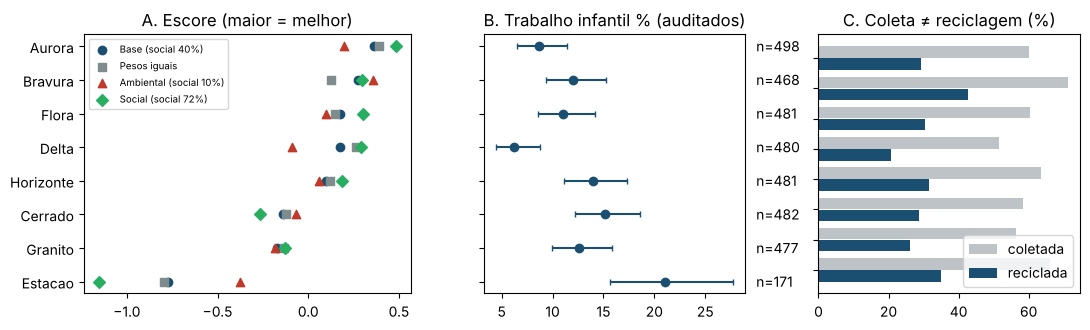

In [9]:
order=S.iloc[:,0].sort_values().index.tolist(); fig,ax=plt.subplots(1,3,figsize=(11,3.4),gridspec_kw={'width_ratios':[1.25,1,1]})
for i,m in enumerate(order):
    for j,n in enumerate(W): ax[0].scatter(S.loc[m,n],i,marker='osD^'[[0,1,3,2][j]] if False else ['o','s','^','D'][j],color=['#1b4f72','#7f8c8d','#c0392b','#27ae60'][j],label=n if i==0 else None)
    x=aud_df[aud_df.marca==m].trabalho_infantil_constatado; k,n_=int(x.sum()),len(x); lo,hi=proportion_confint(k,n_,method='wilson'); p=k/n_
    ax[1].errorbar(100*p,i,xerr=[[100*(p-lo)],[100*(hi-p)]],fmt='o',color='#1b4f72',capsize=2); ax[1].text(30,i,f'n={n_}',va='center')
ax[0].set_yticks(range(8)); ax[0].set_yticklabels(order); ax[0].legend(fontsize=7); ax[0].set_title('A. Escore (maior = melhor)'); ax[1].set_yticks(range(8)); ax[1].set_yticklabels([]); ax[1].set_title('B. Trabalho infantil % (auditados)')
c=df.groupby('marca').coleta_pos_consumo.mean()*100; r=df.groupby('marca').reciclagem_efetiva.mean()*100; y=np.arange(8)
ax[2].barh(y+.2,c[order],.38,color='#bdc3c7',label='coletada'); ax[2].barh(y-.2,r[order],.38,color='#1b4f72',label='reciclada'); ax[2].set_yticks(y); ax[2].set_yticklabels([]); ax[2].legend(); ax[2].set_title('C. Coleta ≠ reciclagem (%)')
plt.tight_layout(); plt.show()

## 8. Conclusões e limitações
- **Estratégia:** comprar **Aurora** como padrão (1ª no esquema-base, de pesos iguais e social; top-2 na maioria dos pesos aleatórios), **devolver 100% das cápsulas à coleta** (sem coleta, 0 reciclagem) e trocar por **Bravura** se a prioridade for clima/reciclagem. **Evitar Estação, Granito e Cerrado.**
- Estação: só ~27% auditada → impacto social **não verificável** (não é "sem irregularidade").
- Os dados **não** mostram ganho de CO₂e ao reciclar (fim de vida ≈35 g em qualquer destino).
- Aurora, Bravura, Flora e Delta são estatisticamente próximas no social; a liderança da Aurora **não é unânime** (depende dos pesos).
- Dados sintéticos; independência por hipótese; comparação apenas entre as 8 marcas; ausentes assumidos aleatórios; pesos são juízo de valor; sem causalidade.